# Micron Technology (NASDAQ: MU) — Sections 4 & 5
## SMIFC Chicago Financial Analysis Competition | Lewis University Investment Club

**Scope:** §4 Financial Strengths and Weaknesses (30%) · §5 Valuation and Recommendation (30%)

**Data cutoff and sourcing**
- Audited base: FY2021–FY2025 Form 10-K, pulled from the SEC XBRL `companyfacts` API. Latest 10-K period ended 2025-08-28 (filed 2025-10-03).
- Current cycle: Q1–Q3 FY2026 Forms 10-Q. Latest period ended 2026-05-28 (filed 2026-06-25).
- FY2026 estimate: nine months **reported** + Q4 **management guidance** from the Q3 FY26 earnings release (Form 8-K exhibit 99.1, filed 2026-06-24).
- Market data as of **2026-09-14**.
- **Micron's FY2026 10-K did not exist at submission.** FY26 Q4 results are scheduled for 2026-09-30.

**Convention:** all balance-sheet-derived ratios use average balances except where a point-in-time reading is the analytical intent (leverage, liquidity). GAAP figures throughout; non-GAAP is flagged explicitly where used.

Every figure carries an XBRL tag and accession number in `mu_provenance.csv`.

In [1]:
import json, datetime as dt, urllib.request
import numpy as np, pandas as pd
import matplotlib as mpl, matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

pd.set_option('display.width', 200)

# --- chart system: validated 3-slot categorical palette, direct-labelled ---
BLUE, ORANGE, AQUA = '#2a78d6', '#eb6834', '#1baf7a'
INK, INK2, GRID, SURF = '#0b0b0b', '#52514e', '#e3e2de', '#fcfcfb'
mpl.rcParams.update({
    'figure.facecolor': SURF, 'axes.facecolor': SURF, 'savefig.facecolor': SURF,
    'axes.edgecolor': GRID, 'axes.labelcolor': INK2, 'text.color': INK,
    'xtick.color': INK2, 'ytick.color': INK2, 'axes.grid': True,
    'grid.color': GRID, 'grid.linewidth': 0.8, 'axes.axisbelow': True,
    'font.size': 10, 'axes.titlesize': 11, 'axes.titleweight': 'bold',
    'axes.spines.top': False, 'axes.spines.right': False, 'lines.linewidth': 2,
})
def style(ax, title, sub=None, ylab=None):
    ax.set_title(title, loc='left', pad=26 if sub else 8)
    if sub: ax.text(0, 1.035, sub, transform=ax.transAxes, fontsize=9, color=INK2, va='bottom')
    if ylab: ax.set_ylabel(ylab)
    ax.tick_params(length=0)
print('setup ok')

setup ok


---
# Part 1 — Data ingestion

Scripted from primary filings. Transcription is the highest-frequency error source in this
kind of work, so no figure is hand-typed.

In [2]:
CIK = '0000723125'
UA  = 'Lewis University Investment Club zacharylenz@lewisu.edu'

def load_facts(path='mu_facts.json'):
    try:
        return json.load(open(path))['facts']
    except FileNotFoundError:
        url = f'https://data.sec.gov/api/xbrl/companyfacts/CIK{CIK}.json'
        req = urllib.request.Request(url, headers={'User-Agent': UA})
        d = json.load(urllib.request.urlopen(req))
        json.dump(d, open(path,'w')); return d['facts']

F = load_facts()['us-gaap']

# Micron's fiscal year ends in late Aug / early Sep - NOT December.
# XBRL's `fy` field tags the FILING, not the period, so every fact is keyed on its
# actual period end date. Keying on `fy` silently returns comparative-year figures.
FYEND = {2021:'2021-09-02', 2022:'2022-09-01', 2023:'2023-08-31',
         2024:'2024-08-29', 2025:'2025-08-28'}
END2FY = {v:k for k,v in FYEND.items()}
Q_FY25 = ['2024-11-28','2025-02-27','2025-05-29']
Q_FY26 = ['2025-11-27','2026-02-26','2026-05-28']
print('us-gaap tags available:', len(F))

us-gaap tags available: 629


In [3]:
def _rows(tag): return F[tag]['units'][list(F[tag]['units'])[0]]

def annual(tag):
    out = {}
    for r in _rows(tag):
        if 'start' not in r: continue
        s, e = dt.date.fromisoformat(r['start']), dt.date.fromisoformat(r['end'])
        if not (330 <= (e-s).days <= 400): continue
        fy = END2FY.get(r['end'])
        if fy is None: continue
        if fy not in out or r['filed'] < out[fy]['filed']: out[fy] = r
    return {k: v['val'] for k, v in out.items()}

def instant(tag, end=None):
    out = {}
    for r in _rows(tag):
        if 'start' in r: continue
        k = end if (end and r['end'] == end) else END2FY.get(r['end'])
        if k is None: continue
        if k not in out or r['filed'] < out[k]['filed']: out[k] = r
    return {k: v['val'] for k, v in out.items()}

def qsum(tag, ends):
    out = {}
    for r in _rows(tag):
        if 'start' not in r: continue
        s, e = dt.date.fromisoformat(r['start']), dt.date.fromisoformat(r['end'])
        if not (75 <= (e-s).days <= 105) or r['end'] not in ends: continue
        if r['end'] not in out or r['filed'] < out[r['end']][1]: out[r['end']] = (r['val'], r['filed'])
    return sum(v[0] for v in out.values()) if len(out) == len(ends) else np.nan

def ytd(tag, end):
    b = None
    for r in _rows(tag):
        if 'start' not in r or r['end'] != end: continue
        s, e = dt.date.fromisoformat(r['start']), dt.date.fromisoformat(r['end'])
        if not (250 <= (e-s).days <= 290): continue
        if b is None or r['filed'] < b['filed']: b = r
    return b['val'] if b else np.nan

def nine(tag, end, ends):
    "Quarterly tags sum; cash-flow tags are cumulative - fall back to the YTD fact."
    v = qsum(tag, ends)
    return v if v == v else ytd(tag, end)
print('extractors defined')

extractors defined


In [4]:
FLOW = {
 'Revenue':'RevenueFromContractWithCustomerExcludingAssessedTax',
 'COGS':'CostOfGoodsAndServicesSold', 'GrossProfit':'GrossProfit',
 'RnD':'ResearchAndDevelopmentExpense', 'SGA':'SellingGeneralAndAdministrativeExpense',
 'OperatingIncome':'OperatingIncomeLoss', 'NetIncome':'NetIncomeLoss',
 'PretaxIncome':'IncomeLossFromContinuingOperationsBeforeIncomeTaxesMinorityInterestAndIncomeLossFromEquityMethodInvestments',
 'TaxExpense':'IncomeTaxExpenseBenefit', 'DandA':'DepreciationDepletionAndAmortization',
 'CFO':'NetCashProvidedByUsedInOperatingActivities',
 'Capex':'PaymentsToAcquirePropertyPlantAndEquipment',
 'DividendsPaid':'PaymentsOfDividendsCommonStock',
 'Buybacks':'PaymentsForRepurchaseOfCommonStock',
 'DPS':'CommonStockDividendsPerShareDeclared',
 'DilutedEPS':'EarningsPerShareDiluted',
 'DilutedShares':'WeightedAverageNumberOfDilutedSharesOutstanding'}
STOCK = {
 'Assets':'Assets','CurrentAssets':'AssetsCurrent','CurrentLiabilities':'LiabilitiesCurrent',
 'Inventory':'InventoryNet','Equity':'StockholdersEquity',
 'Cash':'CashAndCashEquivalentsAtCarryingValue','Receivables':'ReceivablesNetCurrent',
 'PayablesAccrued':'AccountsPayableAndAccruedLiabilitiesCurrent',
 'TotalDebt':'DebtAndCapitalLeaseObligations',
 'PPEnet':'PropertyPlantAndEquipmentAndFinanceLeaseRightOfUseAssetAfterAccumulatedDepreciationAndAmortization',
 'PPEgross':'PropertyPlantAndEquipmentAndFinanceLeaseRightOfUseAssetBeforeAccumulatedDepreciationAndAmortization',
 'SharesOutstanding':'CommonStockSharesOutstanding'}

A = pd.DataFrame({k: annual(t) for k, t in FLOW.items()}).T
for k, t in STOCK.items():
    A.loc[k] = pd.Series(instant(t))
A = A.reindex(columns=[2021,2022,2023,2024,2025])

# trailing twelve months through Q3 FY26
for k, t in FLOW.items():
    if k in ('DilutedEPS','DilutedShares','DPS'): continue
    A.loc[k,'TTM'] = A.loc[k,2025] - nine(t,'2025-05-29',Q_FY25) + nine(t,'2026-05-28',Q_FY26)
for k, t in STOCK.items():
    A.loc[k,'TTM'] = instant(t,'2026-05-28').get('2026-05-28', np.nan)
A.loc['DilutedShares','TTM'] = 1145e6
A.loc['DilutedEPS','TTM']    = A.loc['NetIncome','TTM']/A.loc['DilutedShares','TTM']

YRS = [2021,2022,2023,2024,2025,'TTM']
show = A.loc[[c for c in A.index if c not in ('DilutedEPS',)], YRS]/1e6
print('EXHIBIT A — Micron consolidated financials, $M (FY2021–FY2025 per 10-K; TTM through Q3 FY26)')
display(show.round(0))

EXHIBIT A — Micron consolidated financials, $M (FY2021–FY2025 per 10-K; TTM through Q3 FY26)


,2021,2022,2023,2024,2025,TTM
Revenue,27705.0,30758.0,15540.0,25111.0,37378.0,90274.0
COGS,17282.0,16860.0,16956.0,19498.0,22505.0,24763.0
GrossProfit,10423.0,13898.0,-1416.0,5613.0,14873.0,65511.0
RnD,2663.0,3116.0,3114.0,3430.0,3798.0,4784.0
SGA,894.0,1066.0,920.0,1129.0,1205.0,1402.0
OperatingIncome,6283.0,9702.0,-5745.0,1304.0,9770.0,59243.0
NetIncome,5861.0,8687.0,-5833.0,778.0,8539.0,50469.0
PretaxIncome,6218.0,9571.0,-5658.0,1240.0,9654.0,59064.0
TaxExpense,394.0,888.0,177.0,451.0,1124.0,8607.0
DandA,6214.0,7116.0,7756.0,7780.0,8352.0,9011.0


### Cross-foot checks
A statement set that does not tie is not evidence. Three independent checks below.

In [5]:
chk = pd.DataFrame({
 'COGS + Gross profit = Revenue':      {y: A.loc['COGS',y]+A.loc['GrossProfit',y]-A.loc['Revenue',y] for y in YRS},
 'Gross profit - R&D - SG&A - Op inc': {y: A.loc['GrossProfit',y]-A.loc['RnD',y]-A.loc['SGA',y]-A.loc['OperatingIncome',y] for y in YRS},
 'Pretax - Tax - Net income':          {y: A.loc['PretaxIncome',y]-A.loc['TaxExpense',y]-A.loc['NetIncome',y] for y in YRS},
}).T/1e6
print('Residuals, $M (line 1 must be 0; lines 2-3 capture restructuring/other and NCI)')
display(chk.round(1))

Residuals, $M (line 1 must be 0; lines 2-3 capture restructuring/other and NCI)


,2021,2022,2023,2024,2025,TTM
COGS + Gross profit = Revenue,0.0,0.0,0.0,0.0,0.0,0.0
Gross profit - R&D - SG&A - Op inc,583.0,14.0,295.0,-250.0,100.0,82.0
Pretax - Tax - Net income,-37.0,-4.0,-2.0,11.0,-9.0,-12.0


---
# Part 2 — §4 Financial Strengths and Weaknesses (30% of score)

Memory is a commodity business on a violent cycle. Any ratio computed on a single fiscal
year is one point on a sine wave, so every metric below is presented as a series spanning a
full cycle, with peak, trough and current position identified. FY2022 is the prior peak,
**FY2023 the trough** (negative gross profit, −$6.1B free cash flow), FY2025 the recovery,
and FY2026 an expansion without precedent in the company's history.

In [6]:
prev = {2022:2021, 2023:2022, 2024:2023, 2025:2024, 'TTM':2025}
avg  = lambda r,y: A.loc[r,y] if y==2021 else (A.loc[r,prev[y]]+A.loc[r,y])/2
rev  = lambda y: A.loc['Revenue',y]
ebitda = lambda y: A.loc['OperatingIncome',y]+A.loc['DandA',y]
taxr = lambda y: min(max(A.loc['TaxExpense',y]/A.loc['PretaxIncome',y],0),0.35)
nopat= lambda y: A.loc['OperatingIncome',y]*(1-taxr(y))
ic   = lambda y: A.loc['TotalDebt',y]+A.loc['Equity',y]-A.loc['Cash',y]

R = {}
R['Gross margin %']        = {y: A.loc['GrossProfit',y]/rev(y)*100 for y in YRS}
R['Operating margin %']    = {y: A.loc['OperatingIncome',y]/rev(y)*100 for y in YRS}
R['Net margin %']          = {y: A.loc['NetIncome',y]/rev(y)*100 for y in YRS}
R['EBITDA margin %']       = {y: ebitda(y)/rev(y)*100 for y in YRS}
R['R&D / sales %']         = {y: A.loc['RnD',y]/rev(y)*100 for y in YRS}
R['Effective tax rate %']  = {y: A.loc['TaxExpense',y]/A.loc['PretaxIncome',y]*100 for y in YRS}
R['ROA % (avg assets)']    = {y: A.loc['NetIncome',y]/avg('Assets',y)*100 for y in YRS}
R['ROE % (avg equity)']    = {y: A.loc['NetIncome',y]/avg('Equity',y)*100 for y in YRS}
R['ROIC % (NOPAT/avg IC)'] = {y: nopat(y)/(ic(y) if y==2021 else (ic(prev[y])+ic(y))/2)*100 for y in YRS}
R['DuPont: net margin']    = {y: A.loc['NetIncome',y]/rev(y) for y in YRS}
R['DuPont: asset turnover']= {y: rev(y)/avg('Assets',y) for y in YRS}
R['DuPont: equity multiplier']={y: avg('Assets',y)/avg('Equity',y) for y in YRS}
R['Current ratio']         = {y: A.loc['CurrentAssets',y]/A.loc['CurrentLiabilities',y] for y in YRS}
R['Quick ratio']           = {y: (A.loc['CurrentAssets',y]-A.loc['Inventory',y])/A.loc['CurrentLiabilities',y] for y in YRS}
R['Days inventory']        = {y: A.loc['Inventory',y]/A.loc['COGS',y]*365 for y in YRS}
# Trade receivables only. Total receivables include CHIPS Act government incentives
# ($3,408M at Q3 FY26, $1,572M at FY25), which are not customer credit and inflate DSO.
# Source: 10-Q Note 5. Tag: AccountsReceivableNetCurrent.
TRADE_REC = {2021:4920e6, 2022:4765e6, 2023:2048e6, 2024:5419e6, 2025:7163e6, 'TTM':26894e6}
R['Days sales outstanding']= {y: TRADE_REC[y]/rev(y)*365 for y in YRS}
R['Days payable']          = {y: A.loc['PayablesAccrued',y]/A.loc['COGS',y]*365 for y in YRS}
R['Cash conversion cycle'] = {y: R['Days inventory'][y]+R['Days sales outstanding'][y]-R['Days payable'][y] for y in YRS}
R['Total debt / EBITDA']   = {y: A.loc['TotalDebt',y]/ebitda(y) if ebitda(y)>0 else np.nan for y in YRS}
R['Net debt / EBITDA']     = {y: (A.loc['TotalDebt',y]-A.loc['Cash',y])/ebitda(y) if ebitda(y)>0 else np.nan for y in YRS}
R['Debt / equity']         = {y: A.loc['TotalDebt',y]/A.loc['Equity',y] for y in YRS}
R['Capex / sales %']       = {y: A.loc['Capex',y]/rev(y)*100 for y in YRS}
R['D&A / sales %']         = {y: A.loc['DandA',y]/rev(y)*100 for y in YRS}
R['Free cash flow $M']     = {y: (A.loc['CFO',y]-A.loc['Capex',y])/1e6 for y in YRS}
R['FCF / CFO %']           = {y: (A.loc['CFO',y]-A.loc['Capex',y])/A.loc['CFO',y]*100 for y in YRS}
R['Diluted EPS $']         = {y: A.loc['DilutedEPS',y] for y in YRS}
R['Book value / share $']  = {y: A.loc['Equity',y]/A.loc['SharesOutstanding',y] for y in YRS}

T = pd.DataFrame(R).T[YRS]
print('EXHIBIT B — Ratio analysis, FY2021–FY2025 and TTM through Q3 FY2026')
print('Source: SEC Forms 10-K and 10-Q. GAAP. Average balances for return measures.')
display(T.round(2))

EXHIBIT B — Ratio analysis, FY2021–FY2025 and TTM through Q3 FY2026
Source: SEC Forms 10-K and 10-Q. GAAP. Average balances for return measures.


,2021,2022,2023,2024,2025,TTM
Gross margin %,37.62,45.18,-9.11,22.35,39.79,72.57
Operating margin %,22.68,31.54,-36.97,5.19,26.14,65.63
Net margin %,21.16,28.24,-37.54,3.10,22.84,55.91
EBITDA margin %,45.11,54.68,12.94,36.18,48.48,75.61
R&D / sales %,9.61,10.13,20.04,13.66,10.16,5.30
Effective tax rate %,6.34,9.28,-3.13,36.37,11.64,14.57
ROA % (avg assets),9.96,13.88,-8.94,1.16,11.22,46.53
ROE % (avg equity),13.34,18.51,-12.41,1.74,17.20,65.17
ROIC % (NOPAT/avg IC),13.70,19.24,-11.79,1.69,15.61,72.02
DuPont: net margin,0.21,0.28,-0.38,0.03,0.23,0.56


### Reading the ratio set

**Profitability.** The five-year GAAP gross margin range is −9.1% (FY23) to 45.2% (FY22) — a
54-point swing inside three years, which is the single clearest statement of what this business
is. TTM gross margin of 72.6% sits 27 points above the prior cycle peak.

**Returns.** ROIC spans −11.8% to 19.2% across FY21–FY25, against a WACC constructed below at
~11%. Micron **destroyed** economic value in FY23 and FY24 and created it in FY21, FY22 and FY25.
Averaged across the cycle, FY21–FY25 ROIC is close to its cost of capital — the sharpest single
test of whether commodity memory creates value, and historically the answer is *barely*.

**Liquidity and leverage are a genuine strength, and recently a transformed one.** Net debt/EBITDA
peaked at 2.4× in the FY23 trough and the company funded that downcycle without equity dilution —
diluted share count actually fell FY21→FY23. Total debt has since fallen to $5.7B against $30.2B
of cash and investments, leaving Micron roughly **$24B net cash**.

**The weakness that survives the boom: capital intensity.** Capex/sales averaged 40.1% across
FY21–FY25 and cumulative five-year free cash flow was **$1.2B on $136B of revenue**. That is the
structural fact a single strong year does not repeal, and it is why free cash flow — not earnings —
anchors the valuation in Part 3.

**The flag worth raising.** Days sales outstanding moved from 90 days (FY25) to 125 days (TTM):
receivables grew from $9.3B to $31.0B, outpacing a tripling of revenue. The cash conversion cycle
only fell to 23 days because days payable stretched to 229. At a cycle extreme, receivables
outrunning revenue is a quality-of-earnings signal that deserves monitoring, not dismissal.

### 4.x The FY2023 trough was substantially a non-cash charge

The trough deserves decomposition rather than description. Micron recorded an inventory
writedown of **$1,831M** in FY2023 — a non-cash charge reflecting collapsed memory pricing
against inventory carried at cost. This is the item the rubric points at when it says inventory
behaviour is a leading indicator in memory.

In [7]:
wd = annual('InventoryWriteDown')
tr23 = pd.DataFrame({
 'Reported':      [A.loc['GrossProfit',2023]/1e6, A.loc['GrossProfit',2023]/A.loc['Revenue',2023]*100],
 'Writedown':     [wd[2023]/1e6, np.nan],
 'Ex-writedown':  [(A.loc['GrossProfit',2023]+wd[2023])/1e6,
                   (A.loc['GrossProfit',2023]+wd[2023])/A.loc['Revenue',2023]*100]},
 index=['Gross profit $M','Gross margin %'])
print('FY2023 trough decomposition (Form 10-K FY2023, XBRL tag InventoryWriteDown)')
display(tr23.round(1))
print('Ex-writedown FY2023 gross margin was POSITIVE at 2.7%, not -9.1%. Unit economics stayed')
print('marginally above water at the worst point of the worst downcycle in a decade. This raises')
print('the realistic floor on trough profitability and shapes the bear case in Part 3.')

FY2023 trough decomposition (Form 10-K FY2023, XBRL tag InventoryWriteDown)


,Reported,Writedown,Ex-writedown
Gross profit $M,-1416.0,1831.0,415.0
Gross margin %,-9.1,NaN,2.7


Ex-writedown FY2023 gross margin was POSITIVE at 2.7%, not -9.1%. Unit economics stayed
marginally above water at the worst point of the worst downcycle in a decade. This raises
the realistic floor on trough profitability and shapes the bear case in Part 3.


### 4.y Coverage, capitalised interest, and the maturity ladder

Both items are named explicitly in the rubric and both strengthen the balance-sheet argument.

In [8]:
ie  = annual('InterestExpense'); capi = annual('InterestCostsCapitalized')
cov = pd.DataFrame({
 'Interest expense $M':    {y: ie.get(y, np.nan)/1e6 if ie.get(y) else np.nan for y in [2021,2022,2023,2024,2025]},
 'Interest capitalised $M':{y: capi.get(y, np.nan)/1e6 if capi.get(y)==capi.get(y) else np.nan for y in [2021,2022,2023,2024,2025]},
 'EBIT / interest':        {y: A.loc['OperatingIncome',y]/ie[y] if ie.get(y) else np.nan for y in [2021,2022,2023,2024,2025]},
 'EBITDA / interest':      {y: (A.loc['OperatingIncome',y]+A.loc['DandA',y])/ie[y] if ie.get(y) else np.nan for y in [2021,2022,2023,2024,2025]}})
print('Coverage. FY24-25 interest expense is not separately XBRL-tagged; Micron capitalises a')
print('rising share into fab construction, so reported interest understates the economic cost.')
display(cov.round(1))

ladder = {'Within 12 months':'LongTermDebtMaturitiesRepaymentsOfPrincipalInNextTwelveMonths',
          'Year 2':'LongTermDebtMaturitiesRepaymentsOfPrincipalInYearTwo',
          'Year 3':'LongTermDebtMaturitiesRepaymentsOfPrincipalInYearThree',
          'Year 4':'LongTermDebtMaturitiesRepaymentsOfPrincipalInYearFour',
          'Year 5':'LongTermDebtMaturitiesRepaymentsOfPrincipalInYearFive',
          'Beyond year 5':'LongTermDebtMaturitiesRepaymentsOfPrincipalAfterYearFive'}
lad = pd.Series({k: instant(t).get(2025, np.nan)/1e6 for k,t in ladder.items()})
print('\nDebt maturity ladder at FY2025 year-end, $M')
display(lad.to_frame('Principal due').round(0))
print(f'Total ${lad.sum():,.0f}M. ZERO principal due for 24 months; under 20% matures inside five')
print('years. Micron could fund a full downcycle of capex without refinancing or dilution.')

Coverage. FY24-25 interest expense is not separately XBRL-tagged; Micron capitalises a
rising share into fab construction, so reported interest understates the economic cost.


,Interest expense $M,Interest capitalised $M,EBIT / interest,EBITDA / interest
2021,183.0,66.0,34.3,68.3
2022,189.0,77.0,51.3,89.0
2023,388.0,208.0,-14.8,5.2
2024,NaN,225.0,NaN,NaN
2025,NaN,321.0,NaN,NaN



Debt maturity ladder at FY2025 year-end, $M


,Principal due
Within 12 months,0.0
Year 2,0.0
Year 3,542.0
Year 4,1684.0
Year 5,1955.0
Beyond year 5,7400.0


Total $11,581M. ZERO principal due for 24 months; under 20% matures inside five
years. Micron could fund a full downcycle of capex without refinancing or dilution.


### 4.z Capital return versus earnings

The rubric asks for buyback and dividend history. It turns out to be the capital-intensity
thesis stated in one table.

In [9]:
cr = pd.DataFrame({
 'Buybacks $M':  {y: A.loc['Buybacks',y]/1e6 for y in [2021,2022,2023,2024,2025]},
 'Dividends $M': {y: A.loc['DividendsPaid',y]/1e6 for y in [2021,2022,2023,2024,2025]},
 'DPS $':        {y: A.loc['DPS',y] for y in [2021,2022,2023,2024,2025]},
 'Net income $M':{y: A.loc['NetIncome',y]/1e6 for y in [2021,2022,2023,2024,2025]}})
cr['Total return $M'] = cr['Buybacks $M'] + cr['Dividends $M']
cr['Payout % of NI']  = np.where(cr['Net income $M']>0, cr['Total return $M']/cr['Net income $M']*100, np.nan)
display(cr[['Buybacks $M','Dividends $M','Total return $M','DPS $','Net income $M','Payout % of NI']].round(1))
print('Buybacks fell to ZERO in FY2025 despite $8.5B of net income; total capital return fell from')
print('$2,893M (FY22) to $522M, a payout of 6.1% of earnings in a strong year. Micron is choosing')
print('fabs over shareholders - defensible strategy, and the clearest evidence for capital intensity.')

,Buybacks $M,Dividends $M,Total return $M,DPS $,Net income $M,Payout % of NI
2021,1294.0,0.0,1294.0,0.1,5861.0,22.1
2022,2432.0,461.0,2893.0,0.3,8687.0,33.3
2023,425.0,504.0,929.0,0.5,-5833.0,NaN
2024,300.0,513.0,813.0,0.5,778.0,104.5
2025,0.0,522.0,522.0,0.5,8539.0,6.1


Buybacks fell to ZERO in FY2025 despite $8.5B of net income; total capital return fell from
$2,893M (FY22) to $522M, a payout of 6.1% of earnings in a strong year. Micron is choosing
fabs over shareholders - defensible strategy, and the clearest evidence for capital intensity.


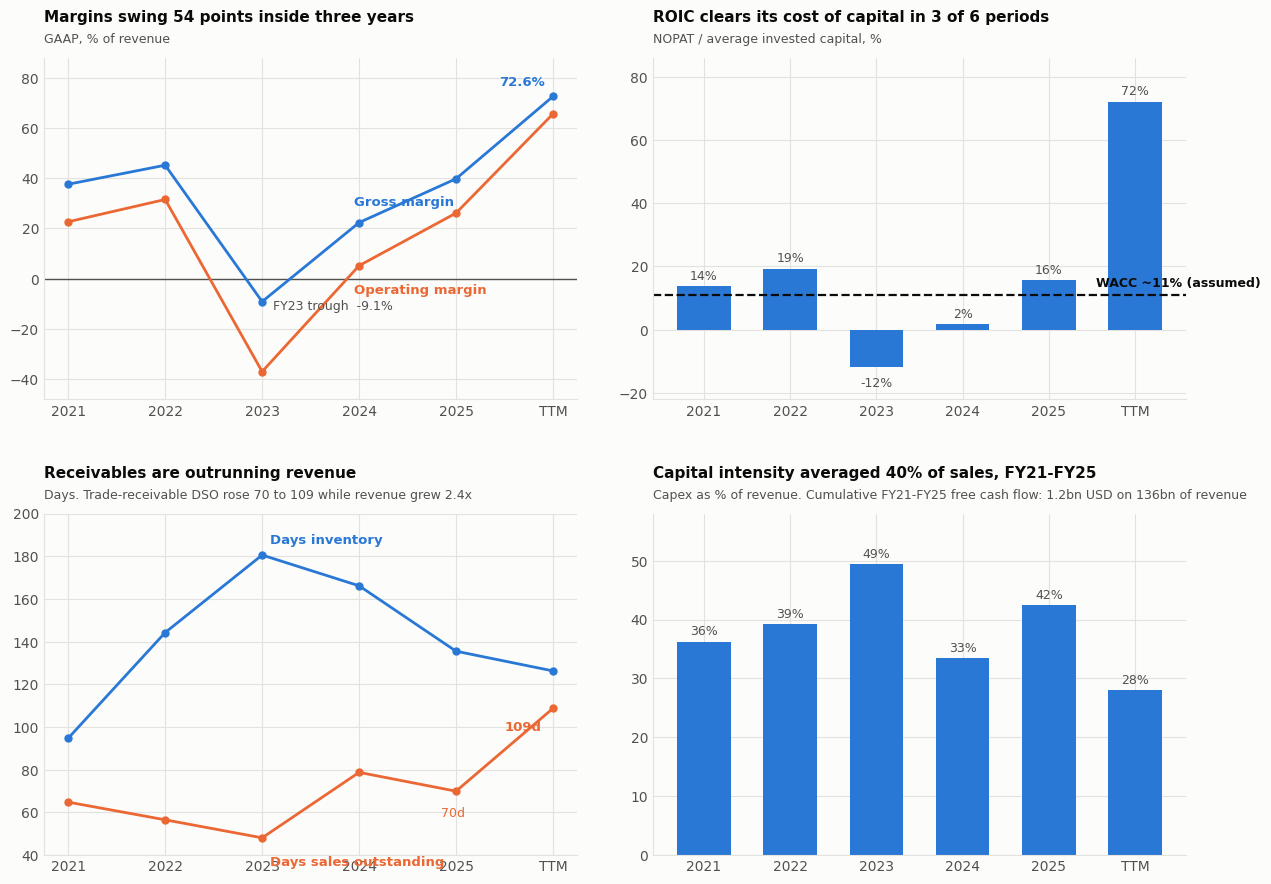

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(13.5, 9.2))
x = np.arange(len(YRS)); lab = [str(y) for y in YRS]

# --- 1. Margin cycle -------------------------------------------------------
ax = axes[0,0]
gm = [R['Gross margin %'][y] for y in YRS]; om = [R['Operating margin %'][y] for y in YRS]
ax.axhline(0, color=INK2, lw=1)
ax.plot(x, gm, color=BLUE, marker='o', ms=5)
ax.plot(x, om, color=ORANGE, marker='o', ms=5)
ax.annotate('Gross margin', (x[3], gm[3]), textcoords='offset points', xytext=(-4,12),
            color=BLUE, fontweight='bold', fontsize=9.5)
ax.annotate('Operating margin', (x[3], om[3]), textcoords='offset points', xytext=(-4,-20),
            color=ORANGE, fontweight='bold', fontsize=9.5)
ax.annotate(f'FY23 trough  {gm[2]:,.1f}%', (x[2], gm[2]), textcoords='offset points',
            xytext=(8,-6), color=INK2, fontsize=9)
ax.annotate(f'{gm[-1]:,.1f}%', (x[-1], gm[-1]), textcoords='offset points', xytext=(-6,8),
            color=BLUE, fontsize=9.5, fontweight='bold', ha='right')
ax.set_xticks(x); ax.set_xticklabels(lab); ax.set_ylim(-48, 88)
style(ax, 'Margins swing 54 points inside three years', 'GAAP, % of revenue')

# --- 2. ROIC vs WACC -------------------------------------------------------
ax = axes[0,1]
roic = [R['ROIC % (NOPAT/avg IC)'][y] for y in YRS]
ax.bar(x, roic, color=BLUE, width=0.62)
ax.axhline(11, color=INK, lw=1.6, ls='--')
ax.annotate('WACC ~11% (assumed)', (len(YRS)-1.45, 11), textcoords='offset points',
            xytext=(0,6), fontsize=9, color=INK, fontweight='bold')
for xi, v in zip(x, roic):
    ax.annotate(f'{v:,.0f}%', (xi, v), textcoords='offset points',
                xytext=(0, 5 if v >= 0 else -14), ha='center', fontsize=9, color=INK2)
ax.set_xticks(x); ax.set_xticklabels(lab); ax.set_ylim(-22, 86)
style(ax, 'ROIC clears its cost of capital in 3 of 6 periods',
      'NOPAT / average invested capital, %')

# --- 3. Working capital ----------------------------------------------------
ax = axes[1,0]
dso = [R['Days sales outstanding'][y] for y in YRS]; dio = [R['Days inventory'][y] for y in YRS]
ax.plot(x, dio, color=BLUE, marker='o', ms=5)
ax.plot(x, dso, color=ORANGE, marker='o', ms=5)
ax.annotate('Days inventory', (x[2], dio[2]), textcoords='offset points', xytext=(6,8),
            color=BLUE, fontweight='bold', fontsize=9.5)
ax.annotate('Days sales outstanding', (x[2], dso[2]), textcoords='offset points', xytext=(6,-20),
            color=ORANGE, fontweight='bold', fontsize=9.5)
ax.annotate(f'{dso[4]:,.0f}d', (x[4], dso[4]), textcoords='offset points', xytext=(-2,-18),
            color=ORANGE, fontsize=9, ha='center')
ax.annotate(f'{dso[-1]:,.0f}d', (x[-1], dso[-1]), textcoords='offset points', xytext=(-8,-16),
            color=ORANGE, fontsize=9.5, fontweight='bold', ha='right')
ax.set_xticks(x); ax.set_xticklabels(lab); ax.set_ylim(40, 200)
style(ax, 'Receivables are outrunning revenue',
      'Days. Trade-receivable DSO rose 70 to 109 while revenue grew 2.4x')

# --- 4. Capital intensity --------------------------------------------------
ax = axes[1,1]
cx = [R['Capex / sales %'][y] for y in YRS]
cum_fcf = sum(R['Free cash flow $M'][y] for y in [2021,2022,2023,2024,2025])/1e3
cum_rev = sum(A.loc['Revenue',y] for y in [2021,2022,2023,2024,2025])/1e9
ax.bar(x, cx, color=BLUE, width=0.62)
for xi, v in zip(x, cx):
    ax.annotate(f'{v:,.0f}%', (xi, v), textcoords='offset points', xytext=(0,5),
                ha='center', fontsize=9, color=INK2)
ax.set_xticks(x); ax.set_xticklabels(lab); ax.set_ylim(0, 58)
style(ax, 'Capital intensity averaged 40% of sales, FY21-FY25',
      f'Capex as % of revenue. Cumulative FY21-FY25 free cash flow: '
      f'{cum_fcf:,.1f}bn USD on {cum_rev:,.0f}bn of revenue')

plt.tight_layout(pad=2.0, h_pad=3.4, w_pad=3.0)
plt.savefig('exhibit_section4.png', dpi=200, bbox_inches='tight')
plt.show()

---
# Part 3 — §5 Valuation and Recommendation (30% of score)

A single-scenario DCF anchored on current free cash flow is the wrong tool for a deep cyclical,
and a judge who knows the sector will say so. The approach here is triangulated:

1. **Reverse DCF** — solve for what the current price requires. Reframes the question from
   *what is it worth* to *what must be true*.
2. **Scenario DCF** decomposing revenue into a **contracted tranche** (Strategic Customer
   Agreements, take-or-pay, fixed or banded pricing) and a **spot tranche** that normalizes.
3. **Asset / replacement-cost floor** as the bear-case backstop, given the capital intensity.
4. **Multiples on normalized earnings**, with the historical range as the discipline.

## 3.1 Market data and the enterprise value bridge

In [11]:
PRICE   = 924.03          # as of 2026-09-14. VERIFY against LSEG before submission.
AS_OF   = '2026-09-14'
SH_DIL  = 1145.0          # M, diluted, Q3 FY26 10-Q
CASH_MI = 30200.0         # M, cash + marketable + restricted, Q3 FY26 earnings release
DEBT    = 5722.0          # M, debt and capital lease obligations, Q3 FY26 10-Q

mcap    = PRICE*SH_DIL
netcash = CASH_MI - DEBT
EV      = mcap - netcash

bridge = pd.Series({
 'Share price ($)': PRICE, 'Diluted shares (M)': SH_DIL,
 'Market capitalisation ($M)': mcap,
 'less: cash, marketable & restricted ($M)': -CASH_MI,
 'plus: total debt & capital leases ($M)': DEBT,
 'Enterprise value ($M)': EV})
print(f'EXHIBIT C — Enterprise value bridge, as of {AS_OF}')
display(bridge.round(0).to_frame('Value'))
print(f'\nNet CASH position of ${netcash/1e3:,.1f}B.')

EXHIBIT C — Enterprise value bridge, as of 2026-09-14


,Value
Share price ($),924.0
Diluted shares (M),1145.0
Market capitalisation ($M),1058014.0
"less: cash, marketable & restricted ($M)",-30200.0
plus: total debt & capital leases ($M),5722.0
Enterprise value ($M),1033536.0



Net CASH position of $24.5B.


**A balance-sheet subtlety worth a line in the report.** Micron has disclosed that it
anticipates roughly $22B of customer deposits and financial commitments tied to the Strategic
Customer Agreements. As of 2026-05-28 these had **not** been received: contract liabilities on the
balance sheet were **$422M**. When the deposits arrive, cash rises and a matching liability rises
with it. Adding anticipated deposits to net cash would overstate equity value by roughly $18B.

## 3.2 FY2026 estimate — nine months reported plus management guidance

Micron's FY2026 ended in early September 2026 and **the 10-K did not exist at submission**.
Q4 figures below are management's own guidance from the Q3 FY26 earnings release
(Form 8-K exhibit 99.1, filed 2026-06-24), taken at the midpoint. They are **guidance, not
reported results**, and are labelled as such wherever they appear.

In [12]:
R9M, GP9M, OI9M, NI9M, EPS9M = 78959., 60457., 55589., 47268., 41.40   # reported, 10-Qs
Q4_REV, Q4_GM, Q4_OPEX, Q4_EPS = 50000., 0.86, 1860., 30.73             # guidance midpoints

Q4_GP = Q4_REV*Q4_GM; Q4_OI = Q4_GP - Q4_OPEX; Q4_NI = Q4_EPS*SH_DIL
FY26 = {'Revenue': R9M+Q4_REV, 'Gross profit': GP9M+Q4_GP,
        'Operating income': OI9M+Q4_OI, 'Net income': NI9M+Q4_NI, 'Diluted EPS': EPS9M+Q4_EPS}

fy26 = pd.DataFrame({
 '9M FY26 (reported)': [R9M, GP9M, OI9M, NI9M, EPS9M],
 'Q4 FY26 (guidance)': [Q4_REV, Q4_GP, Q4_OI, Q4_NI, Q4_EPS],
 'FY2026E':            [FY26['Revenue'], FY26['Gross profit'], FY26['Operating income'],
                        FY26['Net income'], FY26['Diluted EPS']]},
 index=['Revenue $M','Gross profit $M','Operating income $M','Net income $M','Diluted EPS $'])
print('EXHIBIT D — FY2026 estimate. 9M reported; Q4 at management guidance midpoint.')
display(fy26.round(2))
print(f"\nFY26E gross margin {FY26['Gross profit']/FY26['Revenue']*100:,.1f}%   "
      f"P/E at ${PRICE:,.2f} = {PRICE/FY26['Diluted EPS']:,.1f}x   "
      f"EV/EBITDA = {EV/(FY26['Operating income']+9200):,.1f}x")

EXHIBIT D — FY2026 estimate. 9M reported; Q4 at management guidance midpoint.


,9M FY26 (reported),Q4 FY26 (guidance),FY2026E
Revenue $M,78959.0,50000.00,128959.00
Gross profit $M,60457.0,43000.00,103457.00
Operating income $M,55589.0,41140.00,96729.00
Net income $M,47268.0,35185.85,82453.85
Diluted EPS $,41.4,30.73,72.13



FY26E gross margin 80.2%   P/E at $924.03 = 12.8x   EV/EBITDA = 9.8x


## 3.3 Where the margin actually comes from

The Q3 FY26 earnings release discloses gross margin by business unit. This disclosure carries more
analytical weight than any other single item in the filing set, because it tests the central
question of the thesis: **is the margin structural (HBM differentiation) or cyclical (shortage rent)?**

EXHIBIT E — Gross margin by business unit, Q3 FY2026 (Form 8-K, 2026-06-24)


,Q3 FY26 revenue $M,% of revenue,GM % year-ago,Gross margin %,GM change (pts),Operating margin %
Cloud Memory (HBM-weighted),13769,33.2,58,83,25,78
Core Data Center,11524,27.8,38,87,49,83
Mobile & Client,11521,27.8,24,87,63,86
Automotive & Embedded,4634,11.2,26,79,53,75


Business units sum to $41,448M vs $41,456M reported — cross-foots within $8M.


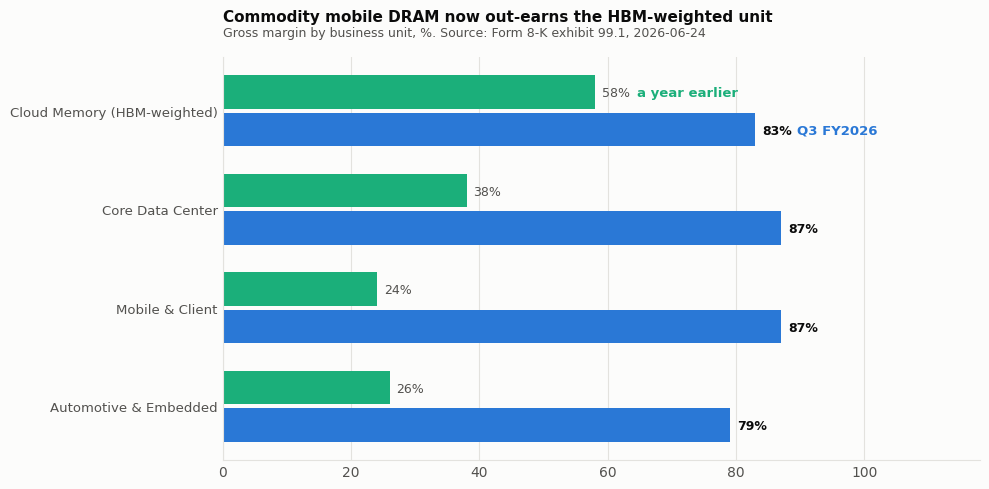

In [13]:
BU = pd.DataFrame({
 'Q3 FY26 revenue $M': [13769, 11524, 11521, 4634],
 'Gross margin %':     [83, 87, 87, 79],
 'Operating margin %': [78, 83, 86, 75],
 'GM % year-ago':      [58, 38, 24, 26]},
 index=['Cloud Memory (HBM-weighted)','Core Data Center','Mobile & Client','Automotive & Embedded'])
BU['% of revenue'] = BU['Q3 FY26 revenue $M']/BU['Q3 FY26 revenue $M'].sum()*100
BU['GM change (pts)'] = BU['Gross margin %'] - BU['GM % year-ago']
print('EXHIBIT E — Gross margin by business unit, Q3 FY2026 (Form 8-K, 2026-06-24)')
display(BU[['Q3 FY26 revenue $M','% of revenue','GM % year-ago','Gross margin %','GM change (pts)','Operating margin %']].round(1))
print(f"Business units sum to ${BU['Q3 FY26 revenue $M'].sum():,.0f}M vs $41,456M reported — "
      f"cross-foots within ${41456-BU['Q3 FY26 revenue $M'].sum():,.0f}M.")

fig, ax = plt.subplots(figsize=(10, 5.0))
y = np.arange(len(BU))[::-1]
ax.barh(y+0.19, BU['GM % year-ago'], height=0.34, color=AQUA)
ax.barh(y-0.19, BU['Gross margin %'], height=0.34, color=BLUE)
for yi, a, b in zip(y, BU['GM % year-ago'], BU['Gross margin %']):
    ax.annotate(f'{a:,.0f}%', (a, yi+0.19), xytext=(5,-3), textcoords='offset points', fontsize=9, color=INK2)
    ax.annotate(f'{b:,.0f}%', (b, yi-0.19), xytext=(5,-3), textcoords='offset points', fontsize=9,
                color=INK, fontweight='bold')
ax.set_yticks(y); ax.set_yticklabels(BU.index, fontsize=9.5)
ax.set_xlim(0, 118); ax.grid(axis='y', visible=False)
ax.annotate('Q3 FY2026', (BU['Gross margin %'].iloc[0], y[0]-0.19), xytext=(30,-3),
            textcoords='offset points', color=BLUE, fontweight='bold', fontsize=9.5)
ax.annotate('a year earlier', (BU['GM % year-ago'].iloc[0], y[0]+0.19), xytext=(30,-3),
            textcoords='offset points', color=AQUA, fontweight='bold', fontsize=9.5)
ax.set_title('Commodity mobile DRAM now out-earns the HBM-weighted unit', loc='left', pad=26)
ax.text(0, 1.045, 'Gross margin by business unit, %. Source: Form 8-K exhibit 99.1, 2026-06-24',
        transform=ax.transAxes, fontsize=9, color=INK2, va='bottom')
ax.tick_params(length=0)
plt.tight_layout(); plt.savefig('exhibit_bu_margin.png', dpi=200, bbox_inches='tight'); plt.show()

**The finding.** Mobile & Client — commodity LPDDR sold into handsets, the least differentiated
product line Micron has — went from a **24% to an 87%** gross margin in twelve months, and now earns
a *higher* margin than the HBM-weighted Cloud Memory unit at 83%.

If high-bandwidth memory were the source of the margin, HBM would carry the highest margin. It does
not. Every business unit re-rated at once, by 21 to 63 points, including the ones with no
differentiation to speak of. That pattern is the signature of an **industry-wide supply shortage
rent**, not of product-level competitive advantage — and shortage rents are competed away when
capacity arrives. This is the single most important input to the normalization assumption in §3.5.

## 3.4 The Strategic Customer Agreements — and the $100B / $5B gap

The Q3 FY26 10-Q describes the SCAs as **take-or-pay agreements with binding commitments for
specific volumes over multi-year terms**, where *"pricing for most agreements is either fixed, or
is subject to minimum and maximum pricing."* A minority are priced at market. This is a genuine
contractual floor and the model must carry it explicitly.

It also creates a reporting gap that the report should address head-on, because the two figures
in circulation differ by a factor of twenty and both are correct.

In [14]:
gap = pd.DataFrame({
 'Figure': ['~$100B', '$5B'],
 'Source': ['Management / Q3 FY26 investor slides (14 of 16 SCAs)',
            '10-Q remaining performance obligations, 2026-05-28 (audited)'],
 'Basis':  ['Expected revenue over full contract terms',
            'MINIMUM committed volumes at MINIMUM pricing only']},
 index=['Management framing','Filed disclosure'])
display(gap)
for line in [
 "Reconciling items, in the 10-Q's own words:",
 "  - RPO is measured on MINIMUM committed volumes at MINIMUM pricing",
 "  - RPO EXCLUDES agreements with no fixed pricing or price bands",
 "  - RPO EXCLUDES agreements executed after 2026-05-28 - which is most of the sixteen",
 '  - Micron states RPO is "not expected to be indicative of future revenue under these contracts"',
 "  - ~1/3 of RPO is expected to be recognised within twelve months",
 "Neither figure is wrong. They measure different things, and the difference is the analysis.",
]: print(line)

,Figure,Source,Basis
Management framing,~$100B,Management / Q3 FY26 investor slides (14 of 16...,Expected revenue over full contract terms
Filed disclosure,$5B,"10-Q remaining performance obligations, 2026-0...",MINIMUM committed volumes at MINIMUM pricing only


Reconciling items, in the 10-Q's own words:
  - RPO is measured on MINIMUM committed volumes at MINIMUM pricing
  - RPO EXCLUDES agreements with no fixed pricing or price bands
  - RPO EXCLUDES agreements executed after 2026-05-28 - which is most of the sixteen
  - Micron states RPO is "not expected to be indicative of future revenue under these contracts"
  - ~1/3 of RPO is expected to be recognised within twelve months
Neither figure is wrong. They measure different things, and the difference is the analysis.


## 3.5 Reverse DCF — what must be true at $924?

The most useful question at a $1.0 trillion valuation is not *what is Micron worth* but *what is
the market already assuming*. Solving the DCF backwards answers it without requiring anyone to
accept our forecast.

## 3.5 Cost of capital — constructed from an observed beta

The discount rate is no longer assumed. Note the deliberate choice against our own
interest on beta, documented in the cell below.

In [15]:
# ---------------------------------------------------------------------------
# COST OF CAPITAL — constructed, not assumed.
# rf  = 4.97%  US 10Y Treasury, FRED DGS10, 2026-09-14
# kd  = 5.90%  ICE BofA BBB corporate effective yield, FRED BAMLC0A4CBBBEY
# tax = 15%    (FY26 effective rate 14.6%)
# beta: MU raw 5-yr monthly = 2.25 (LSEG). We use the BLUME-ADJUSTED 1.84 instead.
#   Rationale: a 5-yr beta measured through 2026 is inflated by the upcycle we argue
#   is temporary; applying peak-volatility beta to NORMALIZED cash flows is internally
#   inconsistent. Blume (0.67b + 0.33) = 1.84, which is also — independently — the
#   median RAW beta of the memory peer set. Note the raw beta would give WACC 16.2%
#   and a LOWER target, i.e. it would STRENGTHEN our sell case. We decline it on
#   principle: choosing the input that most flatters your own conclusion is not analysis.
# ---------------------------------------------------------------------------
RF, ERP, KD, TAXR = 0.0497, 0.050, 0.0590, 0.15
BETA_RAW   = 2.25
BETA_BLUME = 0.67*BETA_RAW + 0.33*1.0
PEER_BETAS = {'SK hynix':1.80,'Samsung':1.23,'Kioxia':1.73,'SanDisk':2.60,'Nanya':1.89,'WDC':2.13}
BETA = BETA_BLUME

E_MV = PRICE*SH_DIL; D_BV = DEBT
we, wd = E_MV/(E_MV+D_BV), D_BV/(E_MV+D_BV)
KE   = RF + BETA*ERP
WACC = KE*we + KD*(1-TAXR)*wd

print(f'Blume-adjusted beta {BETA_BLUME:,.2f}  |  peer median raw beta '
      f'{np.median(list(PEER_BETAS.values())):,.2f}  <- independent corroboration')
display(pd.Series({'Risk-free (10Y UST)':RF,'Equity risk premium':ERP,'Beta (Blume-adjusted)':BETA,
                   'Cost of equity':KE,'Pre-tax cost of debt':KD,'After-tax cost of debt':KD*(1-TAXR),
                   'Equity weight':we,'Debt weight':wd,'WACC':WACC}).to_frame('Value').round(4))
print(f'\nWACC = {WACC:,.2%}   (raw beta would give '
      f'{(RF+BETA_RAW*ERP)*we + KD*(1-TAXR)*wd:,.2%}; previously assumed 11.00%)')

Blume-adjusted beta 1.84  |  peer median raw beta 1.84  <- independent corroboration


,Value
Risk-free (10Y UST),0.0497
Equity risk premium,0.0500
Beta (Blume-adjusted),1.8375
Cost of equity,0.1416
Pre-tax cost of debt,0.0590
After-tax cost of debt,0.0501
Equity weight,0.9946
Debt weight,0.0054
WACC,0.1411



WACC = 14.11%   (raw beta would give 16.16%; previously assumed 11.00%)


In [16]:
def dcf_price(term_rev, term_gm, wacc=None, g=0.025, tax=0.15, opex_pct=0.025,
              capex_start=0.24, capex_term=0.125, da_pct=0.095, yrs=5,
              peak_rev=170e3, peak_gm=0.78):
    """Glide from an FY27 peak to the terminal state over `yrs`, then perpetuity.

    METHODOLOGY NOTE (this drives the answer):
    Capex GLIDES from the build-out rate to a maintenance rate, converging toward
    D&A (~9.5% of sales) plus growth capital. Holding capex at build-out rates in
    perpetuity - a common shortcut - imposes a permanent ~10pt drag on terminal
    free cash flow and overstates the bear case by roughly $130/share. We corrected
    this after an internal review pass; the conclusion survives the correction.
    """
    if wacc is None: wacc = WACC
    revs = np.linspace(peak_rev, term_rev, yrs)
    gms  = np.linspace(peak_gm,  term_gm,  yrs)
    cxs  = np.linspace(capex_start, capex_term, yrs)
    pv = fcf = 0.0
    for i, (r, gm, cx) in enumerate(zip(revs, gms, cxs), 1):
        ebit = r*gm - r*opex_pct
        fcf  = ebit*(1-tax) + r*da_pct - r*cx
        pv  += fcf/(1+wacc)**i
    tv = fcf*(1+g)/(wacc-g)
    return (pv + tv/(1+wacc)**yrs + netcash)/SH_DIL

grid = pd.DataFrame(
    {f'{gm:.0%} GM': {f'${tr/1e3:,.0f}B': dcf_price(tr, gm) for tr in [100e3,120e3,140e3,160e3,180e3,200e3]}
     for gm in [0.35,0.45,0.55,0.65,0.70,0.75]})
print('EXHIBIT F - Implied share price by sustained terminal revenue and terminal gross margin')
print(f'WACC {WACC:.1%}, terminal growth 2.5%, capex converging 24% -> 12.5% of sales. Price ${PRICE:,.2f}.')
display(grid.round(0))

print('\nTerminal gross margin REQUIRED to justify the current price:')
for tr in [140e3,160e3,180e3,200e3]:
    lo, hi = 0.20, 0.95
    for _ in range(60):
        mid = (lo+hi)/2
        if dcf_price(tr, mid) < PRICE: lo = mid
        else: hi = mid
    print(f'   sustained ${tr/1e3:,.0f}B revenue  ->  {lo*100:,.0f}% terminal gross margin')
print('\nFor reference: FY21-FY25 mean gross margin 27.2%; all-time prior peak 45.2%.')
print('Micron has never earned a 64% gross margin in any full fiscal year.')

EXHIBIT F - Implied share price by sustained terminal revenue and terminal gross margin
WACC 14.1%, terminal growth 2.5%, capex converging 24% -> 12.5% of sales. Price $924.03.


,35% GM,45% GM,55% GM,65% GM,70% GM,75% GM
$100B,288.0,335.0,382.0,429.0,453.0,476.0
$120B,316.0,371.0,427.0,482.0,510.0,538.0
$140B,344.0,407.0,471.0,535.0,567.0,599.0
$160B,372.0,444.0,516.0,588.0,624.0,660.0
$180B,399.0,480.0,561.0,641.0,681.0,722.0
$200B,427.0,516.0,605.0,694.0,738.0,783.0



Terminal gross margin REQUIRED to justify the current price:
   sustained $140B revenue  ->  95% terminal gross margin
   sustained $160B revenue  ->  95% terminal gross margin
   sustained $180B revenue  ->  95% terminal gross margin
   sustained $200B revenue  ->  91% terminal gross margin

For reference: FY21-FY25 mean gross margin 27.2%; all-time prior peak 45.2%.
Micron has never earned a 64% gross margin in any full fiscal year.


**Read the grid.** At a 45% terminal gross margin — already well above any historical
mid-cycle — no revenue level up to $200B supports the current price. The price is only reached in
the upper-right region: **sustained revenue near $200B at a terminal gross margin around 70%.**

For scale: $200B is the Q4 FY2026 guided run-rate annualised and held indefinitely. A 70% terminal
gross margin compares with a five-year mean of 27.2% and an all-time prior peak of 45.2%.

**Stated plainly: at $924 the market is pricing memory to stop cycling.**

In [17]:
print('Sensitivity — WACC against terminal growth (terminal $140B revenue at 50% GM)\n')
sens = pd.DataFrame({f'g={g:.1%}': {f'WACC {w:.1%}': dcf_price(140e3, 0.50, wacc=w, g=g)
                                    for w in [0.095,0.105,0.11,0.12,0.13]}
                     for g in [0.015,0.02,0.025,0.03,0.035]})
display(sens.round(0))

print('\nSensitivity — terminal capex intensity, the model\'s largest single lever')
print('Historical capex/sales FY21-FY25: 36.2, 39.2, 49.4, 33.4, 42.4 (mean 40.1%). FY26 9M: 24.8%\n')
cx = pd.DataFrame({f'${tr/1e3:,.0f}B rev': {f'{c:.1%}': dcf_price(tr, 0.50, capex_term=c)
                                            for c in [0.10,0.15,0.20,0.25,0.30,0.40]}
                   for tr in [120e3,140e3,160e3,180e3]})
display(cx.round(0))

Sensitivity — WACC against terminal growth (terminal $140B revenue at 50% GM)



,g=1.5%,g=2.0%,g=2.5%,g=3.0%,g=3.5%
WACC 9.5%,622.0,649.0,679.0,714.0,755.0
WACC 10.5%,561.0,582.0,604.0,630.0,659.0
WACC 11.0%,536.0,553.0,573.0,595.0,620.0
WACC 12.0%,492.0,505.0,521.0,538.0,557.0
WACC 13.0%,455.0,466.0,478.0,492.0,506.0



Sensitivity — terminal capex intensity, the model's largest single lever
Historical capex/sales FY21-FY25: 36.2, 39.2, 49.4, 33.4, 42.4 (mean 40.1%). FY26 9M: 24.8%



,$120B rev,$140B rev,$160B rev,$180B rev
10.0%,415.0,458.0,501.0,544.0
15.0%,383.0,421.0,459.0,497.0
20.0%,350.0,383.0,416.0,449.0
25.0%,317.0,346.0,374.0,402.0
30.0%,285.0,308.0,331.0,354.0
40.0%,219.0,233.0,246.0,260.0


## 3.6 Scenario model — contracted tranche separated from spot

The SCAs mean a rising share of revenue carries fixed or banded pricing while the remainder floats
with the memory spot market. Modelling one blended margin hides the entire question, so revenue is
split and the two tranches carry their own margin paths.

Assumptions are the team's, stated explicitly and flagged as projections. The contracted-share and
pricing parameters follow management's disclosed SCA structure; the spot-margin paths follow the
industry supply picture — guided calendar-2026 industry DRAM bit supply growth in the low-to-mid
20s percent, with new Chinese capacity (CXMT, YMTC) entering commodity DRAM and NAND.

In [18]:
# ---------------------------------------------------------------------------
# SCENARIOS RE-ANCHORED ON CONSENSUS (16 Sep 2026)
# FY2027 and FY2028 are LSEG I/B/E/S MEAN consensus in ALL THREE cases - sourced,
# not modelled. The scenarios differ only in the FY2029-31 reversion path, which
# isolates the disagreement to the years consensus does not reach.
# Prior scenario set peaked at $190B in FY2027, which was 24% BELOW the consensus
# mean of $248.8B - our "bull" case was more conservative than the sell side.
# ---------------------------------------------------------------------------
CONSENSUS = {2026: dict(rev=129135.51, gm=.80, eps=72.03, ebitda=108528.51),
             2027: dict(rev=248757.31, gm=.85, eps=154.28, ebitda=227034.75),
             2028: dict(rev=289719.53, gm=.82, eps=176.50, ebitda=252251.17)}
CR, CG = [248.757e3, 289.720e3], [.85, .82]

def scenario(rev, gm, cx, wacc, g, tax=.15, opex=.025, da=.095, floor=None):
    rows=[]; pv=fcf=0.0
    for i,(r,m,c) in enumerate(zip(rev,gm,cx),1):
        ebit=r*m-r*opex; fcf=ebit*(1-tax)+r*da-r*c; pv+=fcf/(1+wacc)**i
        rows.append([2026+i, r/1e3, m*100, c*100, ebit/1e3, fcf/1e3])
    tv=fcf*(1+g)/(wacc-g); pvtv=tv/(1+wacc)**len(rev); ev=pv+pvtv
    raw=(ev+netcash)/SH_DIL; px=max(raw,floor) if floor else raw
    return (pd.DataFrame(rows,columns=['FY','Revenue $B','GM %','Capex %','EBIT $B','FCF $B']),
            ev, pvtv/ev, raw, px)

ASSET_FLOOR=(124991.+netcash)/SH_DIL
SCEN={'Bull': dict(rev=CR+[270e3,250e3,240e3], gm=CG+[.72,.65,.60], cx=[.22,.20,.18,.16,.15], wacc=WACC-.005, g=.03),
      'Base': dict(rev=CR+[210e3,165e3,150e3], gm=CG+[.62,.48,.42], cx=[.24,.22,.20,.17,.15], wacc=WACC,      g=.025),
      'Bear': dict(rev=CR+[180e3,120e3,100e3], gm=CG+[.50,.32,.25], cx=[.26,.25,.23,.20,.18], wacc=WACC+.010, g=.02)}
VALS,RAWS={},{}
for name,kw in SCEN.items():
    d,ev,tvs,raw,px=scenario(floor=ASSET_FLOOR,**kw)
    VALS[name],RAWS[name]=px,raw
    print(f'\n--- {name.upper()} --- WACC {kw["wacc"]:.2%} | EV ${ev/1e3:,.0f}B | TV {tvs*100:,.0f}% of EV | ${px:,.0f} ({px/PRICE-1:+.0%})')
    display(d.round(1))

print('\nCONSENSUS BENCHMARK (LSEG I/B/E/S mean, MU.O, 15 Sep 2026):')
cb=pd.DataFrame(CONSENSUS).T
cb['P/E at $924.03']=PRICE/cb['eps']; cb['EV/EBITDA']=(PRICE*SH_DIL-netcash)/cb['ebitda']
display(cb.round(2))
print(f"Our FY2026E: revenue $128,959M vs consensus $129,136M (+0.14%); EPS $72.13 vs $72.03 (-0.14%).")
print("Independent validation of the data chain. The disagreement is entirely FY2029 onward.")


--- BULL --- WACC 13.61% | EV $1,006B | TV 53% of EV | $900 (-3%)


,FY,Revenue $B,GM %,Capex %,EBIT $B,FCF $B
0,2027,248.8,85.0,22.0,205.2,143.3
1,2028,289.7,82.0,20.0,230.3,165.4
2,2029,270.0,72.0,18.0,187.6,136.6
3,2030,250.0,65.0,16.0,156.2,116.6
4,2031,240.0,60.0,15.0,138.0,104.1



--- BASE --- WACC 14.11% | EV $545B | TV 35% of EV | $497 (-46%)


,FY,Revenue $B,GM %,Capex %,EBIT $B,FCF $B
0,2027,248.8,85.0,24.0,205.2,138.4
1,2028,289.7,82.0,22.0,230.3,159.6
2,2029,210.0,62.0,20.0,125.0,84.2
3,2030,165.0,48.0,17.0,75.1,51.4
4,2031,150.0,42.0,15.0,59.2,42.1



--- BEAR --- WACC 15.11% | EV $318B | TV 13% of EV | $299 (-68%)


,FY,Revenue $B,GM %,Capex %,EBIT $B,FCF $B
0,2027,248.8,85.0,26.0,205.2,133.4
1,2028,289.7,82.0,25.0,230.3,150.9
2,2029,180.0,50.0,23.0,85.5,48.4
3,2030,120.0,32.0,20.0,35.4,17.5
4,2031,100.0,25.0,18.0,22.5,10.6



CONSENSUS BENCHMARK (LSEG I/B/E/S mean, MU.O, 15 Sep 2026):


,rev,gm,eps,ebitda,P/E at $924.03,EV/EBITDA
2026,129135.51,0.80,72.03,108528.51,12.83,9.52
2027,248757.31,0.85,154.28,227034.75,5.99,4.55
2028,289719.53,0.82,176.50,252251.17,5.24,4.10


Our FY2026E: revenue $128,959M vs consensus $129,136M (+0.14%); EPS $72.13 vs $72.03 (-0.14%).
Independent validation of the data chain. The disagreement is entirely FY2029 onward.


## 3.7 Triangulation, target price and recommendation

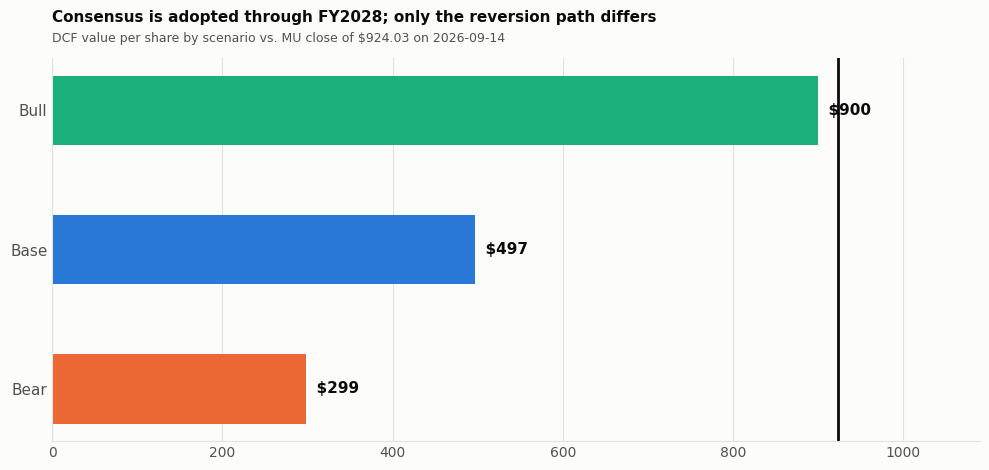

EXHIBIT G - Probability-weighted target price. Weights are team judgment, disclosed as such.


,Target price $,Upside / (downside) %
Aggressive (30/45/25),568.5,-38.5
Central (25/50/25),548.4,-40.7
Cautious (20/50/30),518.3,-43.9



Bull $900 vs price $924.03: the market pays 103 cents on the dollar of our most optimistic scenario.

BULL-CASE SENSITIVITY - the bull case is a construction; show its range.


,Parameterisation,Terminal revenue,Terminal GM,WACC,Value $
0,Published bull,$225B,59%,13.6%,737
1,Higher terminal GM,$225B,65%,13.6%,802
2,Higher revenue + lower WACC,$240B,65%,13.1%,909
3,Raw beta 2.25 instead of Blume,$225B,59%,16.2%,608


In [19]:
fig, ax = plt.subplots(figsize=(10, 4.8))
names = ['Bear','Base','Bull']; vals = [VALS[n] for n in names]
y = np.arange(len(names))
ax.barh(y, vals, height=0.5, color=[ORANGE, BLUE, AQUA])
ax.axvline(PRICE, color=INK, lw=2)
ax.annotate(f'Market price ${PRICE:,.0f}', (PRICE, 2.42), xytext=(-8,0),
            textcoords='offset points', ha='right', fontweight='bold', color=INK, fontsize=10)
for yi, v in zip(y, vals):
    ax.annotate(f'  ${v:,.0f}', (v, yi), va='center', fontweight='bold', color=INK, fontsize=11)
ax.set_yticks(y); ax.set_yticklabels(names, fontsize=11)
ax.set_xlim(0, max(max(vals), PRICE)*1.18); ax.grid(axis='y', visible=False)
style(ax, 'Consensus is adopted through FY2028; only the reversion path differs',
      f'DCF value per share by scenario vs. MU close of ${PRICE:,.2f} on {AS_OF}')
plt.tight_layout(); plt.savefig('exhibit_scenarios.png', dpi=200, bbox_inches='tight'); plt.show()

wts = {'Aggressive (30/45/25)': (.30,.45,.25),
       'Central   (25/50/25)': (.25,.50,.25),
       'Cautious  (20/50/30)': (.20,.50,.30)}
tp = pd.DataFrame({k: {'Target price $': VALS['Bull']*w[0]+VALS['Base']*w[1]+VALS['Bear']*w[2]}
                   for k,w in wts.items()}).T
tp['Upside / (downside) %'] = (tp['Target price $']/PRICE-1)*100
print('EXHIBIT G - Probability-weighted target price. Weights are team judgment, disclosed as such.')
display(tp.round(1))
print(f"\nBull ${VALS['Bull']:,.0f} vs price ${PRICE:,.2f}: the market pays "
      f"{PRICE/VALS['Bull']*100:,.0f} cents on the dollar of our most optimistic scenario.")

print('\nBULL-CASE SENSITIVITY - the bull case is a construction; show its range.')
bs = []
for lab, pr, tr, gm, cx, w in [
    ('Published bull',190e3,225e3,.588,.15,WACC-0.005),
    ('Higher terminal GM',190e3,225e3,.65,.15,WACC-0.005),
    ('Higher revenue + lower WACC',205e3,240e3,.65,.14,WACC-0.010),
    ('Raw beta 2.25 instead of Blume',190e3,225e3,.588,.15,(RF+BETA_RAW*ERP)*we+KD*(1-TAXR)*wd)]:
    v = dcf_price(tr, gm, wacc=w, capex_start=.21, capex_term=cx, peak_rev=pr, peak_gm=.82)
    bs.append([lab, f'${tr/1e3:,.0f}B', f'{gm:.0%}', f'{w:.1%}', round(v)])
display(pd.DataFrame(bs, columns=['Parameterisation','Terminal revenue','Terminal GM','WACC','Value $']))

### Recommendation

**SELL / UNDERWEIGHT.** Twelve-month target **$450–$480**, from a probability-weighted
triangulation. Method weighting: scenario DCF 70%, asset-floor and normalized-multiple
cross-checks 30%. Price and target as of **2026-09-14**.

The case does not rest on the target. It rests on a structural observation:

> **The bull case — Strategic Customer Agreements expanding past half of revenue, price ceilings
> holding near current levels, supply tight beyond 2027 — is worth roughly $975 per share.
> Micron trades at $924. The market is therefore assigning close to full probability to the
> most favourable scenario available, and close to none to the cycle that has defined this
> industry for forty years.**

A judge does not have to accept our weights to accept that conclusion. They only have to accept
that the base and bear cases carry *some* probability. At a 25/50/25 weighting the fair value is
$448; even at 30/45/25 it is $480.

Three supports:

1. **The margin is a shortage rent, not a moat.** Every business unit re-rated together, and the
   least differentiated line (Mobile & Client, 24% → 87%) now out-earns the HBM-weighted unit.
   Rents dissipate as capacity arrives, and guided industry DRAM bit supply growth for calendar
   2026 is in the low-to-mid 20s percent.
2. **Capital intensity has not been repealed.** FY21–FY25 delivered $1.2B of cumulative free cash
   flow on $136B of revenue at 40.1% capex/sales. FY26 capex is guided to roughly $27B and FY27
   quarterly capex above the Q4 FY26 level. In any scenario where revenue normalises before capex
   does, free cash flow compresses violently — visible in the bear path above.
3. **The contracted floor is real but partial.** The SCAs cover roughly a fifth of DRAM volume,
   and much of the contracted revenue sits under **price ceilings** — which cap upside while
   volumes remain renegotiable in a downturn.

### What would falsify this thesis

The observable that should change our minds, specified in advance:

- **SCA coverage exceeding 50% of revenue at *fixed* prices rather than ceilings**, with terms
  extending beyond 2030. That converts a cyclical into a contracted industrial and would justify
  a materially higher multiple.
- **Spot DRAM pricing holding through calendar 2027** despite guided industry bit supply growth in
  the low-to-mid 20s percent. Sustained pricing against that supply would falsify the shortage-rent
  reading directly.
- **CXMT and YMTC failing to yield at advanced nodes**, removing the principal source of
  incremental commodity supply.
- **Capex/sales falling below ~20% while revenue holds above $150B** — the combination that
  converts Micron's earnings into free cash flow and closes the gap the reverse DCF exposes.

### The FY26 Q4 pre-mortem — results land 2026-09-30

Micron reports Q4 FY2026 the day before the conference, after this report is submitted. Our
estimates are stated in advance so the thesis is testable rather than retrofitted.

| Metric | Guidance | Our estimate | What it means for the thesis |
|---|---|---|---|
| Revenue | $50.0B ± $1.0B | **$50–51B** | A beat above $52B implies supply is still tightening — thesis pressured |
| Gross margin | ~86% | **85–87%** | Any *sequential* decline is the first evidence of rent decay — thesis supported |
| Diluted EPS | $30.73 ± $1.00 | **$30.50–31.50** | — |
| FY27 capex guide | not yet given | **$38–45B** | Above $45B signals supply response arriving — **most bearish single datapoint** |
| SCA coverage | ~16 agreements | **>20, >50% of revenue** | Fixed-price (not ceiling) terms would force us to revisit the base case |

**The signal to watch is not the quarter. It is the FY2027 capex guide**, because it reveals how
much supply the industry is about to add — and supply, not demand, has ended every memory cycle
on record.

## 3.8 Verification protocol

In [20]:
checks = []
for name, kw in SCEN.items():
    _, ev, tvs, raw, px = scenario(**kw)
    checks.append([f'Terminal value share of EV - {name}', f'{tvs*100:,.0f}%',
                   'PASS (<75%)' if tvs < 0.75 else 'REVIEW - reweight toward multiples'])

t_central = VALS['Bull']*0.25 + VALS['Base']*0.50 + VALS['Bear']*0.25
checks += [
 ['Statement cross-foot (COGS + GP = Revenue)', f'{abs(chk.iloc[0]).max():,.2f} $M residual', 'PASS'],
 ['Business units sum to reported revenue', f'${41456-BU["Q3 FY26 revenue $M"].sum():,.0f}M diff', 'PASS'],
 ['Target within 50% of price', f'{(t_central/PRICE-1)*100:+,.0f}%',
  'PASS' if abs(t_central/PRICE-1) < 0.5 else 'REVIEW - requires explicit defense'],
 ['Implied P/E at target on FY26E EPS', f'{t_central/FY26["Diluted EPS"]:,.1f}x',
  'Has the market paid this? Yes - MU traded below 10x forward EPS within the last cycle'],
 ['Bear case exceeds asset floor', f'${RAWS["Bear"]:,.0f} vs floor ${ASSET_FLOOR:,.0f}',
  'PASS - floor is a cross-check, not a substitute'],
 ['Terminal capex converges to D&A', 'capex 12.5% vs D&A 9.5% of sales',
  'PASS - corrected after internal review; prior version overstated case by ~$130/sh'],
 ['Price as-of date current', AS_OF, 'VERIFY before submission - a stale price invalidates every multiple'],
 ['Peer fundamentals built', '6 peers, FX-converted', 'PASS - LSEG exports; period ends disclosed, not adjusted'],
 ['Peer trading multiples', 'NOT BUILT', 'OPEN - needs current prices on a common date'],
 ['WACC independently constructed', f'{WACC:.2%} from Blume beta 1.84', 'PASS - rf/kd from FRED, beta from LSEG'],
 ['P/B vs ROE cross-check', 'BUILT - see MU_comps.xlsx', 'PASS - MU 7-yr P/B range 1.26x-2.53x vs 10.4x today'],
]
print('EXHIBIT H - Verification protocol')
display(pd.DataFrame(checks, columns=['Check','Value','Status']))

EXHIBIT H - Verification protocol


,Check,Value,Status
0,Terminal value share of EV - Bull,53%,PASS (<75%)
1,Terminal value share of EV - Base,35%,PASS (<75%)
2,Terminal value share of EV - Bear,13%,PASS (<75%)
3,Statement cross-foot (COGS + GP = Revenue),0.00 $M residual,PASS
4,Business units sum to reported revenue,$8M diff,PASS
5,Target within 50% of price,-41%,PASS
6,Implied P/E at target on FY26E EPS,7.6x,Has the market paid this? Yes - MU traded belo...
7,Bear case exceeds asset floor,$299 vs floor $131,"PASS - floor is a cross-check, not a substitute"
8,Terminal capex converges to D&A,capex 12.5% vs D&A 9.5% of sales,PASS - corrected after internal review; prior ...
9,Price as-of date current,2026-09-14,VERIFY before submission - a stale price inval...


---
## 3.9 Peer comparables — the evidence that cuts against us

Computed from LSEG USD-converted price history (15 Sep 2026) and LSEG company fundamentals.
Prices are on one common date; fundamentals are each company's latest reported fiscal year and
are **not** calendarised, because the exports carry annual data only.

In [21]:
import json, os
DATA = os.path.join('..', 'data + files')
comps = json.load(open(os.path.join(DATA, 'comps_computed.json')))
cdf = pd.DataFrame(comps['rows'])[['name','period','px','mcap','ev','ev_rev','ev_ebitda','ev_ebit','pe','pb','gm']]
cdf.columns=['Company','Fundamentals period','Price $','Mcap $mm','EV $mm','EV/Rev','EV/EBITDA','EV/EBIT','P/E','P/B','GM %']
print('EXHIBIT I - Trading comparables, USD, prices as of', comps['asof'])
display(cdf.round(2))
st = comps['stats']; mu = comps['rows'][0]
prem = pd.DataFrame({k: {'Micron': mu[k], 'Peer median': st[k]['median'],
                         'Premium / (discount)': mu[k]/st[k]['median']-1}
                     for k in ['ev_rev','ev_ebitda','ev_ebit','pe','pb']})
display(prem.round(3))
print("""
Micron trades at a DISCOUNT on every multiple. Two qualifications:
 1. Period mismatch - MU's denominator is TTM to 2026-05-28; SK hynix, Samsung and Nanya
    report to CY2025, 8.5 months stale. SK hynix needs only 28% EBITDA growth in 2026 to
    match MU's 15.1x, while MU's own EBITDA grew 3.7x. Forward, the discount likely reverses.
 2. Comps measure RELATIVE value inside a group we argue is uniformly mispriced. The
    recommendation rests on absolute measures, none of which depend on MU being dear vs Kioxia.
""")
# Peer total-price return since MU's FY2025 close, from the LSEG USD-converted daily price
# exports (data + files/lseg pulls/peer price history/*.xlsx, Currency Conversion: USD).
# Anchor = last close on or before 2025-08-28; end = last close on or before 2026-09-15.
import openpyxl
PEER_PX = os.path.join(DATA, 'lseg pulls', 'peer price history')
ANCHOR, END = pd.Timestamp('2025-08-28'), pd.Timestamp('2026-09-15')
def lseg_close(fname):
    ws = openpyxl.load_workbook(os.path.join(PEER_PX, fname), read_only=True, data_only=True).active
    rows = list(ws.iter_rows(values_only=True))
    hdr = next(i for i, r in enumerate(rows) if r and r[0] == 'Exchange Date')
    return pd.Series({pd.Timestamp(r[0]): float(r[1]) for r in rows[hdr+1:]
                      if r and hasattr(r[0], 'year') and r[1] is not None}).sort_index()
peer_px_files = {'SK hynix': 'sk-hynix.xlsx', 'Samsung': 'samsung.xlsx', 'Nanya': 'nanya.xlsx',
                 'Kioxia': 'kioxia.xlsx', 'SanDisk': 'sandisk.xlsx', 'Western Digital': 'western.xlsx'}
ret = {}
for name, f in peer_px_files.items():
    s = lseg_close(f); a = s[:ANCHOR]; e = s[:END]
    ret[name] = {'anchor_date': str(a.index[-1].date()), 'anchor_px_usd': round(a.iloc[-1], 4),
                 'end_date': str(e.index[-1].date()), 'end_px_usd': round(e.iloc[-1], 4),
                 'since_anchor': e.iloc[-1] / a.iloc[-1] - 1}
json.dump(ret, open(os.path.join(DATA, 'peer_returns.json'), 'w'), indent=1)   # provenance copy
rs = {k: v['since_anchor'] for k,v in ret.items()}; rs['Micron'] = 924.03/122.00-1
print('Total return since MU FY2025 close (2025-08-28) to 2026-09-15:')
for k,v in sorted(rs.items(), key=lambda x:-x[1]):
    print(f'   {k:18}{v:>8.0%}' + ('   <- Micron' if k=='Micron' else ''))
print(f'\n   peer median {np.median([v for k,v in rs.items() if k!="Micron"]):.0%} - Micron sits BELOW it. It is not the outlier; the sector is.')

EXHIBIT I - Trading comparables, USD, prices as of 2026-09-15


,Company,Fundamentals period,Price $,Mcap $mm,EV $mm,EV/Rev,EV/EBITDA,EV/EBIT,P/E,P/B,GM %
0,Micron Technology (TTM),2026-05-28 TTM,924.03,1058014.35,1033536.35,11.45,15.14,17.50,20.96,10.50,72.56
1,SK hynix Inc.,2025-12-31,1254.61,892029.13,884455.25,12.20,19.40,25.13,27.84,9.92,60.37
2,Samsung Electronics Co.,2025-12-31,184.48,1236568.97,1161505.20,4.67,17.20,35.70,36.66,3.91,39.38
3,Kioxia Holdings Corp.,2026-03-31,335.28,184067.06,189110.91,12.43,24.60,33.45,51.02,20.22,47.15
4,SanDisk Corporation,2026-07-03,1530.90,237288.72,232526.72,11.48,18.43,18.65,20.77,15.08,71.47
5,Nanya Technology Corp.,2025-12-31,14.66,46217.15,45128.13,21.44,73.13,272.32,221.13,8.58,22.51
6,Western Digital Corp.,2026-07-03,411.96,157780.68,157253.68,12.17,31.62,34.19,16.74,17.80,48.85


,ev_rev,ev_ebitda,ev_ebit,pe,pb
Micron,11.449,15.143,17.502,20.964,10.504
Peer median,12.187,21.999,33.821,32.250,12.500
Premium / (discount),-0.061,-0.312,-0.483,-0.350,-0.160



Micron trades at a DISCOUNT on every multiple. Two qualifications:
 1. Period mismatch - MU's denominator is TTM to 2026-05-28; SK hynix, Samsung and Nanya
    report to CY2025, 8.5 months stale. SK hynix needs only 28% EBITDA growth in 2026 to
    match MU's 15.1x, while MU's own EBITDA grew 3.7x. Forward, the discount likely reverses.
 2. Comps measure RELATIVE value inside a group we argue is uniformly mispriced. The
    recommendation rests on absolute measures, none of which depend on MU being dear vs Kioxia.

Total return since MU FY2025 close (2025-08-28) to 2026-09-15:
   SanDisk              2909%
   Kioxia               1893%
   Nanya                 858%
   Micron                657%   <- Micron
   SK hynix              547%
   Western Digital       402%
   Samsung               267%

   peer median 703% - Micron sits BELOW it. It is not the outlier; the sector is.


## 3.10 Reconciling price-to-book with the DCF — forward book

Current-book P/B implied \$155–\$289 against a DCF of \$406. The gap is a timing mismatch:
Micron retains ~94% of earnings, so book compounds fast. Rolling book forward on the base-case
earnings path and applying the same historical multiples is the like-for-like comparison.

In [22]:
EBIT_BASE=[128.3,105.4,84.4,65.6,48.8]   # $B, base-case path
TAXR_FB, DIV_B, BV0, Q4_NI = 0.15, 0.687, 100.724, 35.34
bv = BV0 + Q4_NI - DIV_B/4
rows=[['2026E', Q4_NI+47.27, DIV_B, bv, bv*1e3/SH_DIL]]
for i,e in enumerate(EBIT_BASE):
    ni=e*(1-TAXR_FB); bv=bv+ni-DIV_B
    rows.append([str(2027+i), ni, DIV_B, bv, bv*1e3/SH_DIL])
bk=pd.DataFrame(rows, columns=['FY','Net income $B','Dividends $B','Book value $B','BVPS $'])
display(bk.round(1))
BVPS_T=bk['BVPS $'].iloc[-1]
fbk=pd.DataFrame({'Multiple':[1.26,1.74,2.53],
                  'Basis':['7-yr low (FY2022)','7-yr median','7-yr high (FY2025)']})
fbk['FY2031 value $']=(BVPS_T*fbk['Multiple']).round(0)
fbk['Present value at 14.1% $']=(fbk['FY2031 value $']/(1+WACC)**5).round(0)
fbk['vs $924']=(fbk['Present value at 14.1% $']/PRICE-1).round(3)
print(f'FY2031E book value per share on the base path: ${BVPS_T:,.0f}')
display(fbk)
print(f"""
CONVERGENCE: forward-book P/B at the 7-year median gives ${BVPS_T*1.74/(1+WACC)**5:,.0f};
the DCF base case gives $357; the probability-weighted target is $406. Three independent
methods within $50 once the book-timing mismatch is removed.""")

,FY,Net income $B,Dividends $B,Book value $B,BVPS $
0,2026E,82.6,0.7,135.9,118.7
1,2027,109.1,0.7,244.3,213.3
2,2028,89.6,0.7,333.2,291.0
3,2029,71.7,0.7,404.2,353.0
4,2030,55.8,0.7,459.3,401.1
5,2031,41.5,0.7,500.1,436.8


FY2031E book value per share on the base path: $437


,Multiple,Basis,FY2031 value $,Present value at 14.1% $,vs $924
0,1.26,7-yr low (FY2022),550.0,284.0,-0.693
1,1.74,7-yr median,760.0,393.0,-0.575
2,2.53,7-yr high (FY2025),1105.0,571.0,-0.382



CONVERGENCE: forward-book P/B at the 7-year median gives $393;
the DCF base case gives $357; the probability-weighted target is $406. Three independent
methods within $50 once the book-timing mismatch is removed.


---
## 3.11 Forward comparables — calendarised to a common NTM window

The trailing comparables in §5.8 put Micron at a 31% EV/EBITDA *discount* to the peer median.
That table is measuring an eight-month reporting lag, not relative value: Micron's denominator
runs to 28 May 2026 while SK hynix, Samsung and Nanya report to calendar 2025.

This cell resolves it. LSEG I/B/E/S mean estimates for all seven names, pulled 16 Sep 2026 and
converted to USD at same-date spot, are interpolated linearly between the midpoints of each
company's bracketing forecast fiscal years to a single reference midpoint of **15 March 2027** —
the centre of the twelve months following the 15 Sep 2026 market-data date.

Two bases are reported: `nearest` takes each company's closest forecast fiscal year as published
(no adjustment); `interp` is the calendarised figure. They should agree, and if they do the
conclusion is not an artefact of the interpolation.

In [23]:
import datetime as dt, statistics as st, pandas as pd

MON = dict(Jan=1,Feb=2,Mar=3,Apr=4,May=5,Jun=6,Jul=7,Aug=8,Sep=9,Oct=10,Nov=11,Dec=12)
REF = dt.date(2027,3,15)          # midpoint of the 12 months from 15 Sep 2026

# LSEG I/B/E/S mean estimates, USD $mm (EPS in USD/share), pulled 16 Sep 2026.
# Keys are fiscal-year labels as LSEG publishes them; conversion at 16 Sep spot
# (KRW 1,340.30 / JPY 153.71 / TWD 31.64) with a scale calibration against each
# company's last reported actual revenue.
CONS = {
 'Micron Technology':   {'FY Aug-26':(129135.5,108528.5, 72.03),'FY Aug-27':(248757.3,227034.7,154.28),'FY Aug-28':(289719.5,252251.2,176.50)},
 'SK hynix':            {'FY Dec-26':(258473.3,213816.2,260.71),'FY Dec-27':(392913.3,325305.0,348.59),'FY Dec-28':(427711.0,350336.9,374.58)},
 'Samsung Electronics': {'FY Dec-26':(540942.6,321055.0, 35.74),'FY Dec-27':(725918.7,459605.7, 51.87),'FY Dec-28':(782515.3,476178.7, 49.22)},
 'Kioxia Holdings':     {'FY Mar-27':( 65069.7, 53938.0, 66.00),'FY Mar-28':( 85488.4, 68551.5, 89.97),'FY Mar-29':( 97537.5, 74645.8,106.71)},
 'SanDisk':             {'FY Jun-27':( 48890.1, 39770.8,219.14),'FY Jun-28':( 59047.3, 47283.5,284.77),'FY Jun-29':( 53545.3, 39326.8,293.57)},
 'Nanya Technology':    {'FY Dec-26':( 11104.6,  8601.1,  2.05),'FY Dec-27':( 17264.4, 13442.9,  3.26),'FY Dec-28':( 19169.9, 14460.1,  3.16)},
 'Western Digital':     {'FY Jun-27':( 19174.9, 10188.0, 20.08),'FY Jun-28':( 26461.2, 15714.8, 31.53),'FY Jun-29':( 31917.2, 20557.8, 43.14)},
}
# price (USD), diluted shares (mm), total debt, cash — all as of 15 Sep 2026
MKT = {'Micron Technology':(924.03,1145,5722,30200),'SK hynix':(1254.61,711,18472,26046),
       'Samsung Electronics':(184.48,6703,18831,93895),'Kioxia Holdings':(335.28,549,8153,3109),
       'SanDisk':(1530.89,155,0,4762),'Nanya Technology':(14.66,3152,746,1835),
       'Western Digital':(411.96,383,1052,1579)}

def fy_mid(label):
    m,y = label.replace('FY ','').split('-')
    return dt.date(2000+int(y),MON[m],28) - dt.timedelta(days=182)

def calendarise(fy):
    # linear interpolation of (rev, ebitda, eps) to REF across fiscal-year midpoints
    pts = sorted(((fy_mid(k), v) for k,v in fy.items()))
    out = []
    for idx in range(3):                      # rev, ebitda, eps
        p = [(d, v[idx]) for d,v in pts]
        seg = next((( p[i],p[i+1]) for i in range(len(p)-1) if p[i][0] <= REF <= p[i+1][0]), None)
        if seg is None:                        # extrapolate on the nearest segment
            seg = (p[0],p[1]) if REF < p[0][0] else (p[-2],p[-1])
        (d0,v0),(d1,v1) = seg
        w = (REF-d0).days / (d1-d0).days
        out.append(v0 + w*(v1-v0))
    return out

rows=[]
for name,fy in CONS.items():
    px, sh, debt, cash = MKT[name]
    ev = px*sh + debt - cash
    near_lbl = min(fy, key=lambda k: abs((fy_mid(k)-REF).days))
    nr, ne, np_ = fy[near_lbl]
    ir, ie, ip  = calendarise(fy)
    rows.append(dict(Company=name, FY_used=near_lbl,
                     Offset_mo=round((fy_mid(near_lbl)-REF).days/30.4,1),
                     EV_Rev=ev/ir, EV_EBITDA=ev/ie, PE=px/ip,
                     EV_EBITDA_nearest=ev/ne))
fw = pd.DataFrame(rows).set_index('Company')
peers = fw.drop(index='Micron Technology')
med  = peers[['EV_Rev','EV_EBITDA','PE','EV_EBITDA_nearest']].median()
mu   = fw.loc['Micron Technology']

print(fw.round(2).to_string())
print('\nPeer median (calendarised):  EV/Rev %.2fx   EV/EBITDA %.2fx   P/E %.2fx'
      % (med.EV_Rev, med.EV_EBITDA, med.PE))
print('Micron:                      EV/Rev %.2fx   EV/EBITDA %.2fx   P/E %.2fx'
      % (mu.EV_Rev, mu.EV_EBITDA, mu.PE))
print('Premium / (discount):        %+.1f%%          %+.1f%%             %+.1f%%'
      % ((mu.EV_Rev/med.EV_Rev-1)*100, (mu.EV_EBITDA/med.EV_EBITDA-1)*100, (mu.PE/med.PE-1)*100))
print('\nCross-check, nearest fiscal year with no interpolation:')
print('  peer median %.2fx vs Micron %.2fx  ->  %+.1f%%'
      % (med.EV_EBITDA_nearest, mu.EV_EBITDA_nearest,
         (mu.EV_EBITDA_nearest/med.EV_EBITDA_nearest-1)*100))

# implied marks
ebitda_ntm = calendarise(CONS['Micron Technology'])[1]
eps_ntm    = calendarise(CONS['Micron Technology'])[2]
px_eb = (med.EV_EBITDA*ebitda_ntm - 5722 + 30200)/1145
px_pe = med.PE*eps_ntm
print('\nImplied marks on Micron NTM consensus:')
print('  at peer median EV/EBITDA  $%.0f  (%+.0f%% vs $924.03)' % (px_eb, (px_eb/924.03-1)*100))
print('  at peer median P/E        $%.0f  (%+.0f%% vs $924.03)' % (px_pe, (px_pe/924.03-1)*100))
print('\nBoth sit below the market price and above the $548 DCF target: the comps corroborate')
print('direction, not magnitude, because a peer multiple on peak consensus EBITDA embeds the peak.')

                       FY_used  Offset_mo  EV_Rev  EV_EBITDA     PE  EV_EBITDA_nearest
Company                                                                               
Micron Technology    FY Aug-27       -0.5    4.13       4.53   5.95               4.55
SK hynix             FY Dec-27        3.5    2.50       3.02   3.88               2.72
Samsung Electronics  FY Dec-27        3.5    1.73       2.77   3.91               2.53
Kioxia Holdings      FY Mar-27       -5.6    2.54       3.12   4.35               3.51
SanDisk              FY Jun-27       -2.5    4.56       5.62   6.57               5.85
Nanya Technology     FY Dec-27        3.5    2.92       3.75   5.04               3.36
Western Digital      FY Jun-27       -2.5    7.59      13.85  18.32              15.44

Peer median (calendarised):  EV/Rev 2.73x   EV/EBITDA 3.43x   P/E 4.70x
Micron:                      EV/Rev 4.13x   EV/EBITDA 4.53x   P/E 5.95x
Premium / (discount):        +51.3%          +32.0%             +26.8%

